# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import OpenSARShipDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader
import numpy as np 

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/OpenSARShip/",
    "csv_file": "./data/OpenSARShip/train.csv", 
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = OpenSARShipDataset(dataset_config)
print(f"Total number of patches: {len(dataset)}")

Total number of patches: 12558


## Show images from the dataset

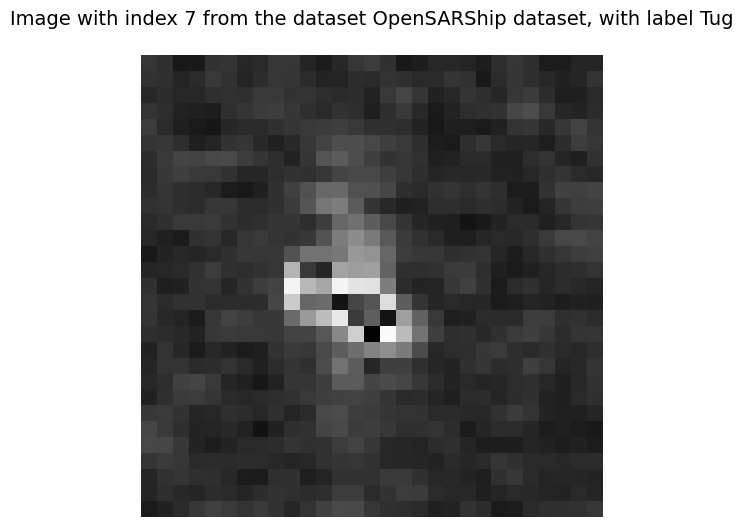

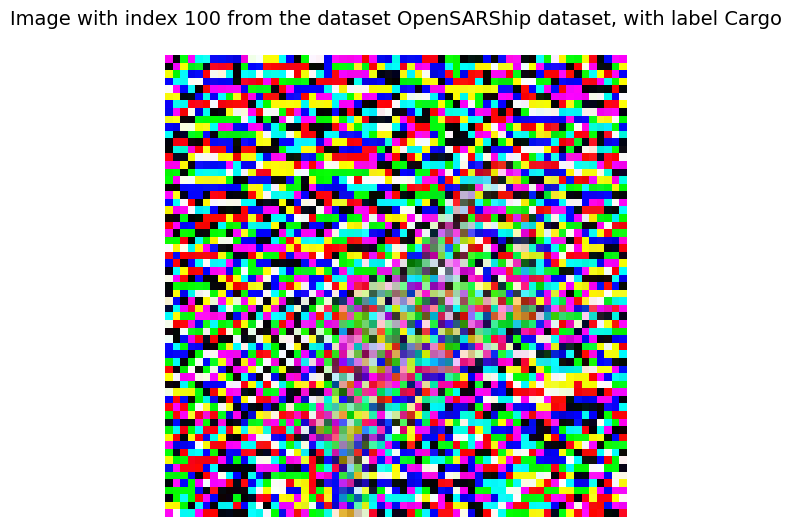

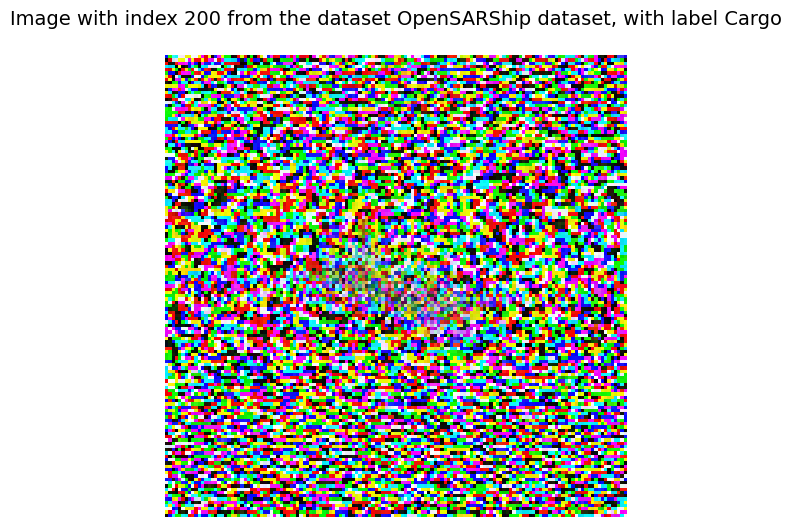

In [5]:
fig1 = dataset.show_image(7)
fig2 = dataset.show_image(100)
fig3 = dataset.show_image(200)

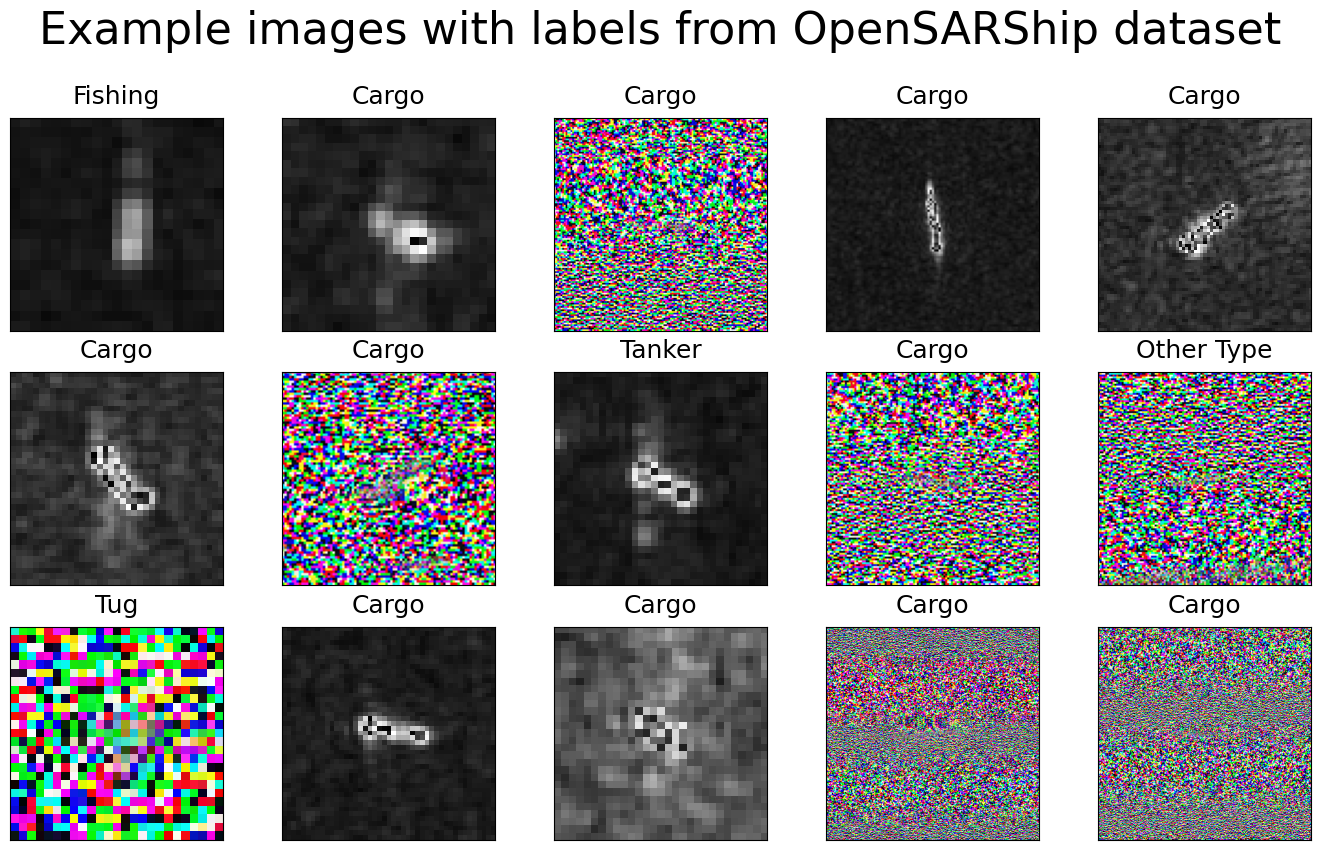

In [72]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [79]:
dataset.show_samples()

,File name,Label
0,images/S1A_IW_GRDH_1SDV_20160116T095421_201601...,Cargo
1,images/S1A_IW_GRDH_1SDV_20150926T102506_201509...,Cargo
2,images/S1A_IW_SLC__1SDV_20160324T102458_201603...,Dredging
3,images/S1A_IW_GRDH_1SDV_20150926T102506_201509...,Tanker
4,images/S1A_IW_GRDH_1SDV_20160328T112449_201603...,Other Type
5,images/S1A_IW_GRDH_1SDV_20160421T095422_201604...,Cargo
6,images/S1A_IW_SLC__1SSV_20141219T204259_201412...,Cargo
7,images/S1A_IW_GRDH_1SDV_20160312T102458_201603...,Cargo
8,images/S1A_IW_GRDH_1SDV_20160712T221240_201607...,Tug
9,images/S1A_IW_GRDH_1SDV_20150926T102506_201509...,Tanker


In [86]:
dataset.data_distribution_table()

,Label,Count
0,Anti-pollution equipment,1
1,Cargo,7901
2,Diving ops,1
3,Dredging,33
4,Dredging or underwater ops,121
5,Fishing,161
6,High speed craft,12
7,Law Enforcement,30
8,Other Type,1634
9,Passenger,77


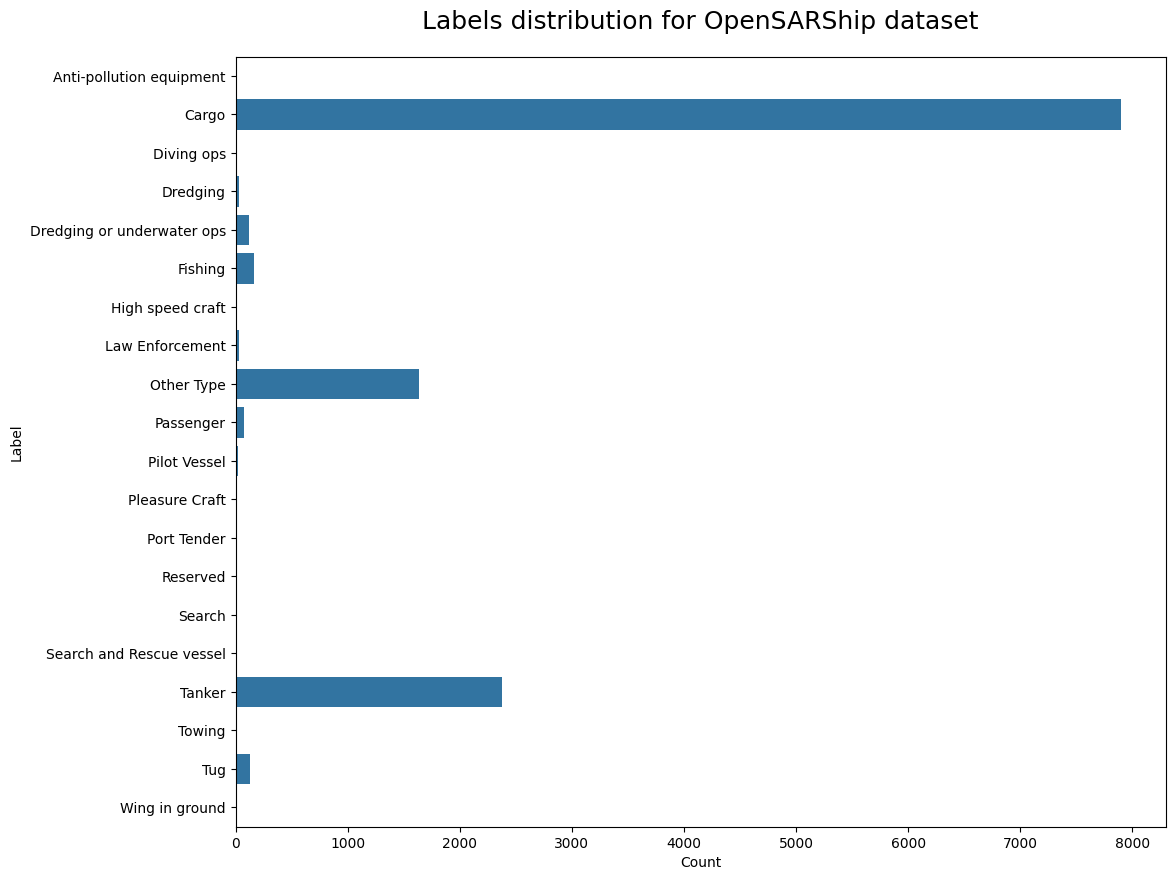

In [87]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/OpenSARShip/",
    "csv_file": "./data/OpenSARShip/train.csv",
}

train_dataset = OpenSARShipDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/OpenSARShip/",
    "csv_file": "./data/OpenSARShip/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = OpenSARShipDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(12558, 1568)

## Setup and create the model for training

In [ ]:
epochs = 20
model_directory = "./data/experiments/OpenSARShip/"
model_config = {
    "num_classes": 20, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-06-10 08:18:01,221 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-06-10 08:18:01,603 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [92]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-06-10 08:18:02,961 INFO Starting training.
training: 100%|██████████| 393/393 [01:39<00:00,  3.93it/s]
2025-06-10 08:19:42,980 INFO epoch: 1, time: 99, loss:  1.07923
testing on train set: 100%|██████████| 393/393 [00:35<00:00, 11.07it/s]
2025-06-10 08:20:21,377 INFO Accuracy:0.6427775123427297, Precision Micro:0.6427775123427297, Precision Macro:0.06322055187602907, Precision Weighted:0.4855759934260911, Precision per Class:[0.6434433  0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.62096774
 0.         0.        ], Recall Micro:0.6427775123427297, Recall Macro:0.0566951257301334, Recall Weighted:0.6427775123427297, Recall per Class:[0.99253165 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.14137087
 0.         0.        ], F1_score Micro:0.6427775123

0.6999649406333774

## Predictions

2025-06-10 09:18:48,731 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/OpenSARShip/checkpoint.pth.tar
2025-06-10 09:18:49,104 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/OpenSARShip/checkpoint.pth.tar at epoch 21


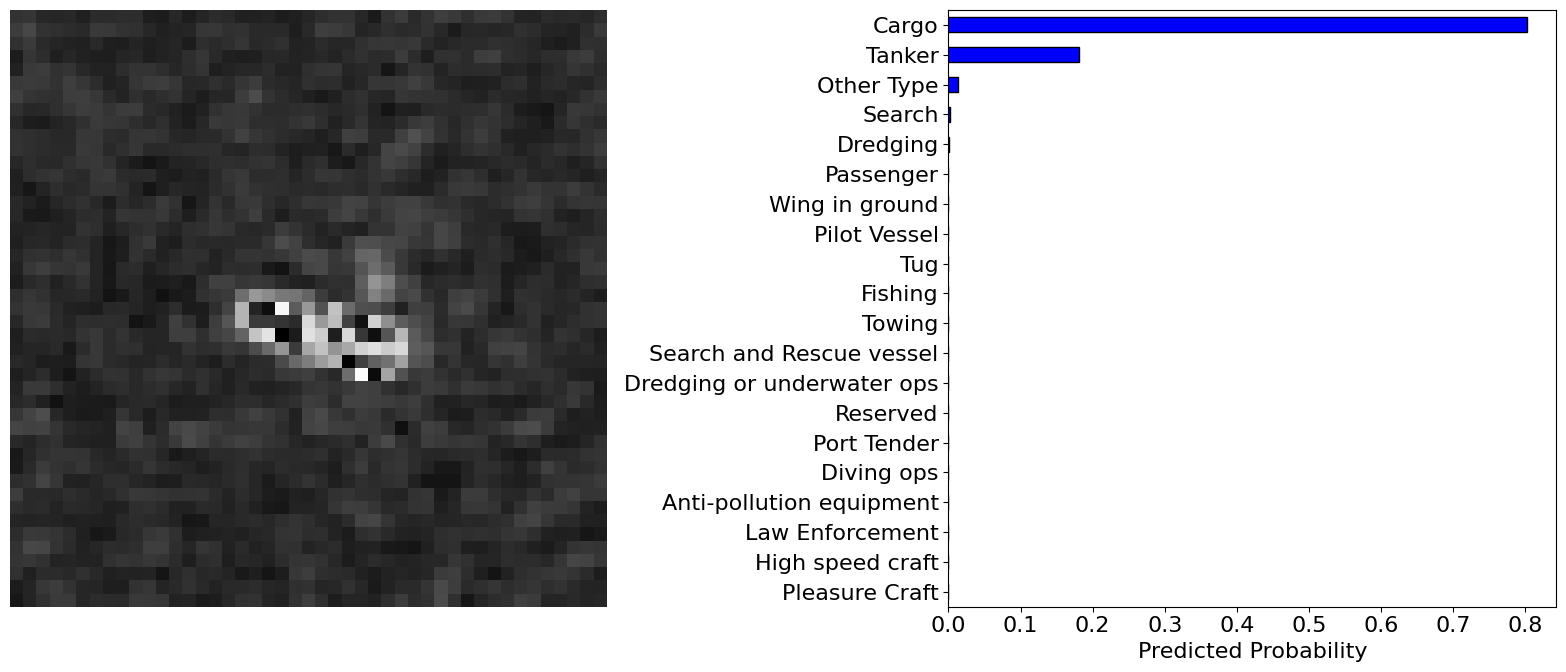

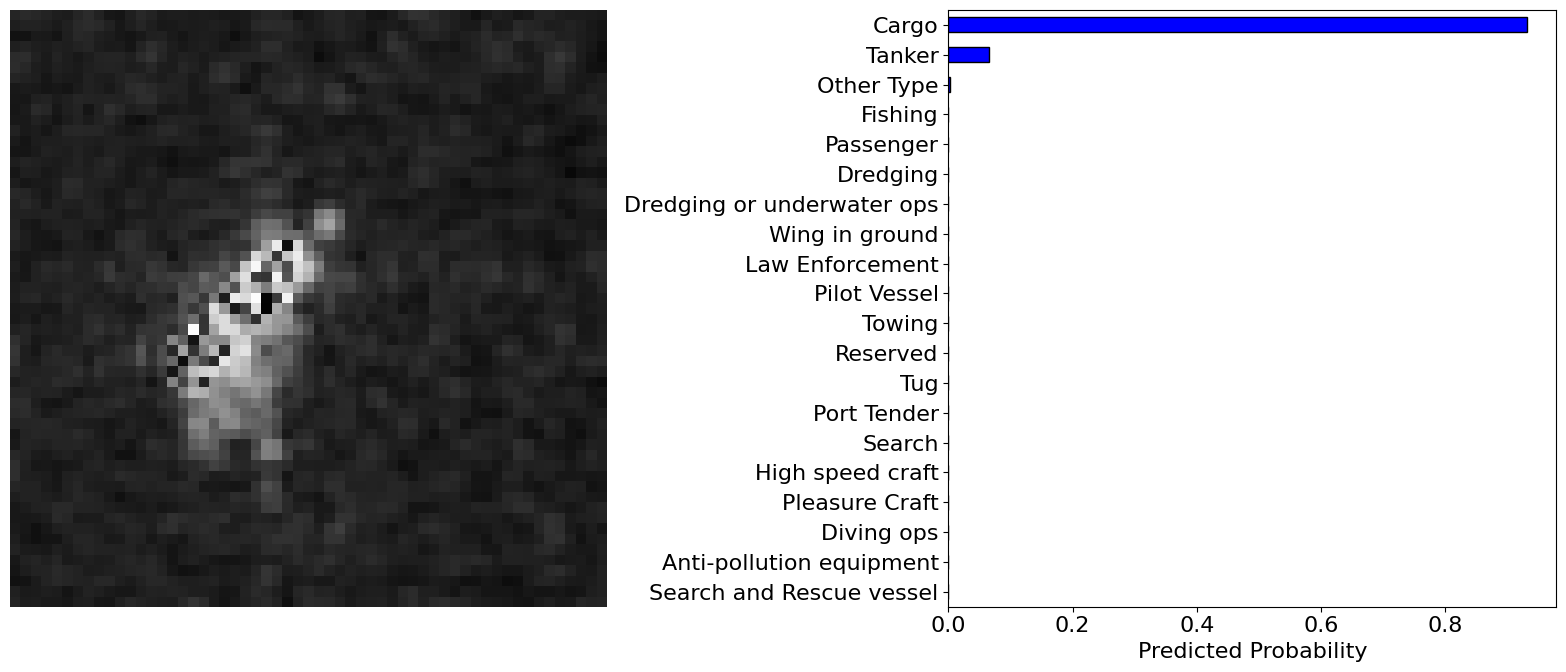

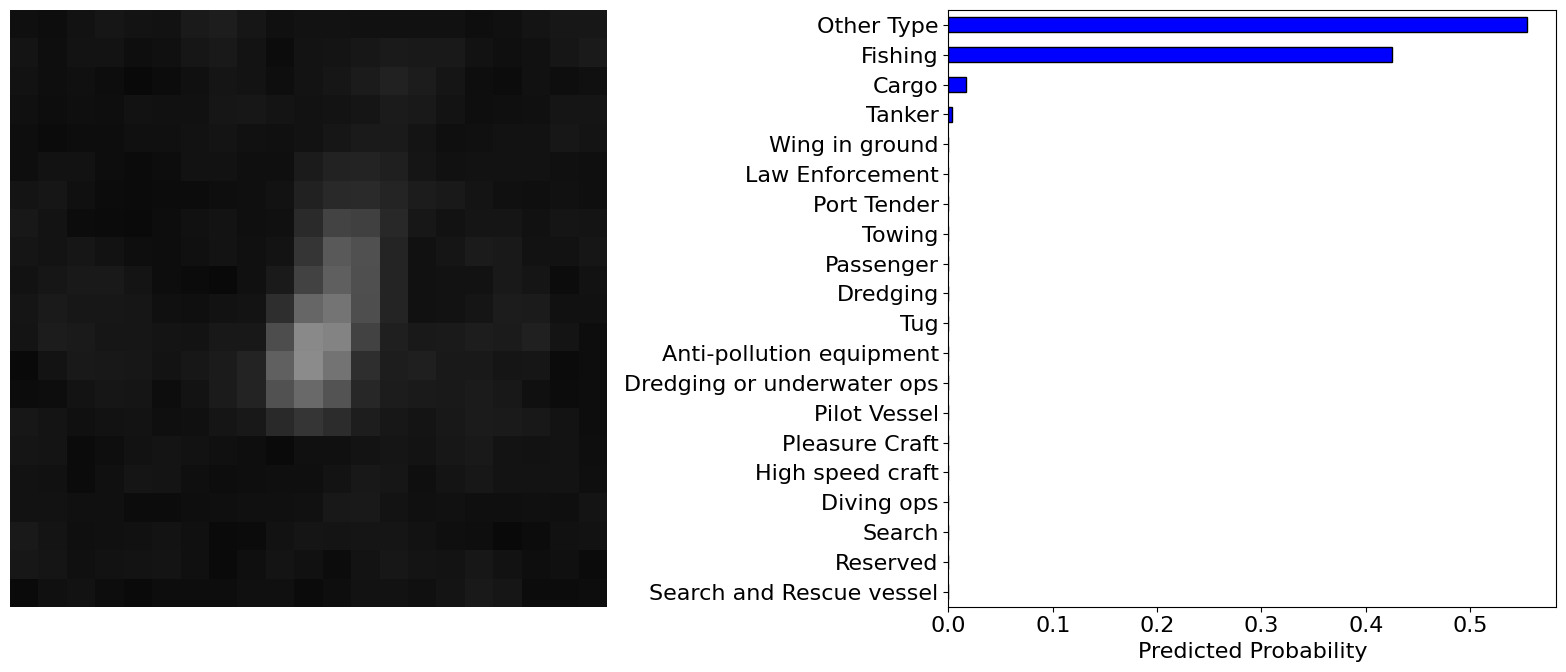

In [ ]:
labels = ["Cargo","Tanker","Passenger","Law Enforcement","Anti-pollution equipment","Port Tender","Search",
            "Search and Rescue vessel","Pilot Vessel","High speed craft","Diving ops","Dredging","Dredging or underwater ops",
            "Towing","Fishing","Wing in ground","Tug","Other Type","Reserved","Pleasure Craft"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/OpenSARShip/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/OpenSARShip/images/S1A_IW_GRDH_1SDV_20160511T102500_20160511T102530_011210_010F14_D8FA_Tanker_x8420_y7832.tif')
image = image.astype(np.uint8)
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/OpenSARShip/images/S1A_IW_GRDH_1SDV_20160219T221225_20160219T221250_010021_00EBE1_C9D5_Cargo_x11028_y13839.tif')
image = image.astype(np.uint8)
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/OpenSARShip/images/S1A_IW_GRDH_1SDV_20150918T095428_20150918T095453_007768_00ACD0_1804_Fishing_x21091_y282.tif')
image = image.astype(np.uint8)
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)